Apply the Savitzky-Golay filter:
* savgol_filter(data['Close'], window_length=15, polyorder=3)
* data['Close']: The data to smooth.
* window_length: The size of the sliding window (must be odd). Larger values mean more smoothing.
polyorder: The order of the polynomial used for fitting (lower values mean less complex smoothing).

Plot the data:
The original and smoothed data are plotted to visualize the effect of the filter.
Key points:
* Choosing window_length and polyorder:
These parameters are crucial. Experiment with different values to find the best balance between smoothing and preserving important features of the data.
* Handling edge effects:
The filter may introduce artifacts at the edges of the data. You can use the mode parameter in savgol_filter to handle this (e.g., mode='nearest').

https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.savgol_filter.html


In [ ]:
from datetime import datetime

import pandas as pd
import numpy as np
from attr import dataclass
from scipy.signal import savgol_filter

import matplotlib.pyplot as plt

# Sample data
data = pd.DataFrame({
    'Date': pd.date_range(start='2023-01-01', periods=100),
    'Close': np.random.randn(100).cumsum() + 100
})

# Apply Savitzky-Golay filter
data['Smoothed'] = savgol_filter(data['Close'], window_length=15, polyorder=3)

# Plot the original and smoothed data
plt.plot(data['Close'], label='Original')
plt.plot(data['Smoothed'], label='Smoothed')
plt.legend()
plt.show()

Index(['Close'], dtype='object')
                                 Close
Date                                  
2023-11-20 00:00:00+00:00  2022.239136
2023-11-21 00:00:00+00:00  1937.066772
2023-11-22 00:00:00+00:00  2064.425293
2023-11-23 00:00:00+00:00  2062.210693
2023-11-24 00:00:00+00:00  2081.152100


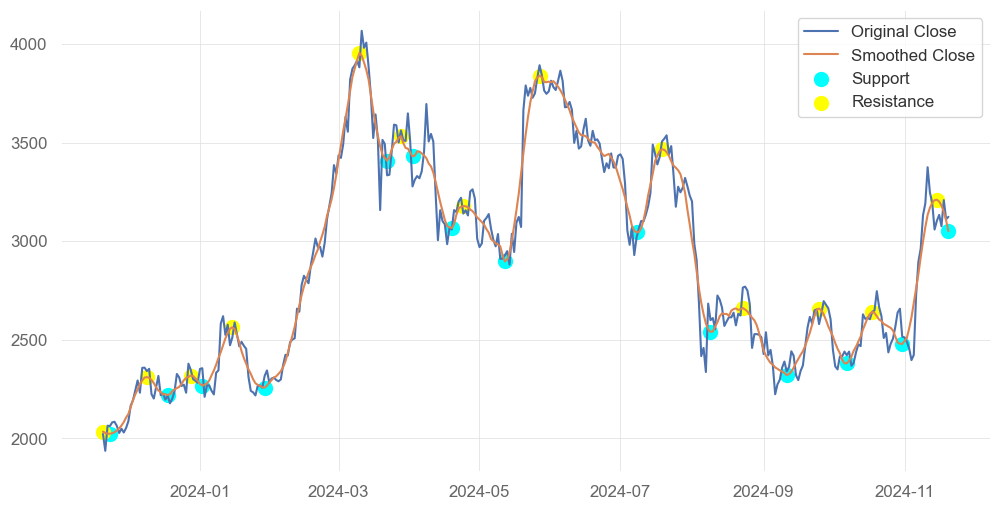

In [384]:
import pandas as pd
from scipy.signal import savgol_filter, argrelextrema
import matplotlib.pyplot as plt
import yfinance as yf

ticker = 'ETH-USD'
time_period = '1y'

btc = yf.Ticker(ticker)
data = btc.history(period=time_period)

# Display the first few rows of the data
df = pd.DataFrame({
    'Close': data['Close'],
})
print(df.columns)
df = df.astype({
    'Close': 'float32'
},
    copy=False)

print(df.head())

# Adjust window_length and polyorder based on your data
window_length = 19  # Should be an odd integer
polyorder = 2
df['smoothed_close'] = savgol_filter(df['Close'], window_length, polyorder)

# Find local minima and maxima
df['min'] = df.iloc[argrelextrema(df['smoothed_close'].values, np.less_equal, order=5)[0]]['smoothed_close']
df['max'] = df.iloc[argrelextrema(df['smoothed_close'].values, np.greater_equal, order=5)[0]]['smoothed_close']

plt.figure(figsize=(12, 6))
plt.plot(df['Close'], label='Original Close')
plt.plot(df['smoothed_close'], label='Smoothed Close')
plt.scatter(df.index, df['min'], color='cyan', label='Support', s=100)
plt.scatter(df.index, df['max'], color='yellow', label='Resistance', s=100)
plt.legend()
plt.show()

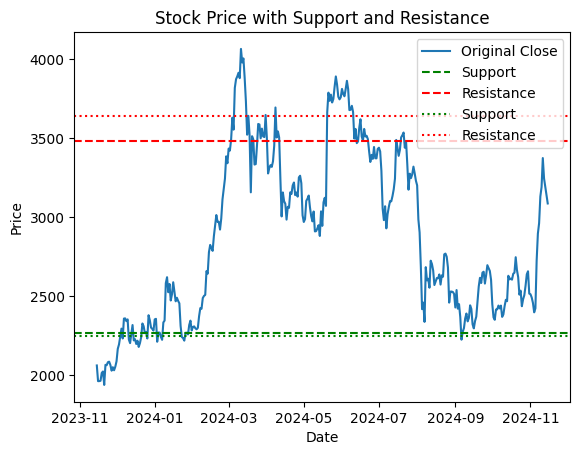

In [248]:

support = df['min'].quantile(0.25)
resistance = df['max'].quantile(0.75)

support_2 = df['min'].quantile(0.15)  # Optional: Add additional support levels
resistance_2 = df['max'].quantile(0.85)

# Plot the data
plt.plot(df['Close'], label='Original Close')

# Add horizontal lines for support and resistance
plt.axhline(y=support, color='green', linestyle='--', label='Support')
plt.axhline(y=resistance, color='red', linestyle='--', label='Resistance')

# Add horizontal lines for support and resistance
plt.axhline(y=support_2, color='green', linestyle='dotted', label='Support')
plt.axhline(y=resistance_2, color='red', linestyle='dotted', label='Resistance')
# Customize the plot
plt.title('Stock Price with Support and Resistance')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.show()

In [246]:

import talib
import yfinance as yf
import matplotlib.pyplot as plt


# Function to get historical price data
def get_price_data(ticker, start_date, end_date):
    data = yf.download(ticker, start=start_date, end=end_date)
    return data


# Function to implement Parabolic SAR trading strategy
def parabolic_sar_strategy(data):
    # Calculate Parabolic SAR
    data['SAR'] = talib.SAR(data['High'], data['Low'], acceleration=0.02, maximum=0.2)

    # Generate trading signals
    data['Signal'] = 0  # 0 means no signal
    data['Signal'] = np.where((data['Close'] > data['SAR']), 1, -1)  # Buy or Sell signal

    # Generate positions based on signals
    data['Position'] = data['Signal'].diff()
    return data


# Function to plot the strategy results
def plot_strategy(data):
   plt.figure(figsize=(12, 6))
   plt.plot(data['Close'], label='Close Price', color='cyan')
   plt.scatter(data[data['Signal'] == 1].index, data[data['Signal'] == 1]['Close'], marker='^', color='g', label='Buy Signal')
   plt.scatter(data[data['Signal'] == -1].index, data[data['Signal'] == -1]['Close'], marker='v', color='r', label='Sell Signal')
   plt.plot(data['SAR'], label='Parabolic SAR', linestyle='dashed', color='yellow')
   plt.title('Parabolic SAR Trading Strategy')
   plt.xlabel('Date')
   plt.ylabel('Price')
   plt.legend()
   plt.show()

In [ ]:
ticker = 'BTC-USD'

btc = yf.Ticker(ticker)
data = btc.history(period=time_period)
print(data.head())


                                  Open         High          Low        Close  \
Date                                                                            
2024-11-10 00:00:00+00:00  3130.729248  3249.914062  3073.248779  3191.331299   
2024-11-11 00:00:00+00:00  3191.656982  3389.529297  3109.769531  3374.812988   
2024-11-12 00:00:00+00:00  3375.154785  3444.154053  3211.198486  3246.257324   
2024-11-13 00:00:00+00:00  3244.543213  3337.877197  3121.666016  3192.595947   
2024-11-15 00:00:00+00:00  3058.191895  3091.508545  3038.368652  3087.041016   

                                Volume  Dividends  Stock Splits    trendline  \
Date                                                                           
2024-11-10 00:00:00+00:00  47418730187        0.0           0.0  3017.587035   
2024-11-11 00:00:00+00:00  55417771668        0.0           0.0  3018.410324   
2024-11-12 00:00:00+00:00  56686078066        0.0           0.0  3019.233613   
2024-11-13 00:00:00+00:00  52010

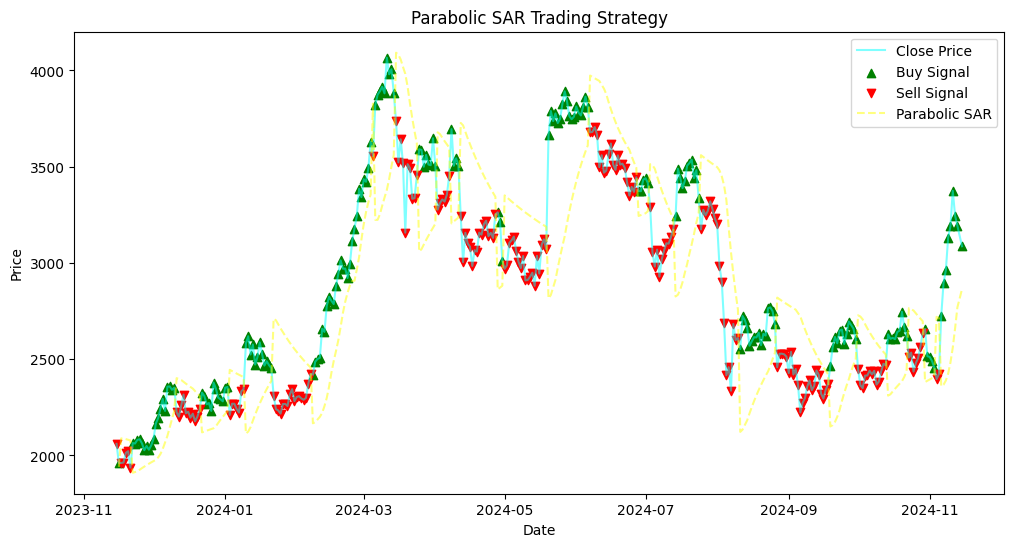

In [254]:
strategy_data = parabolic_sar_strategy(data)
print(strategy_data.tail())
plot_strategy(strategy_data)

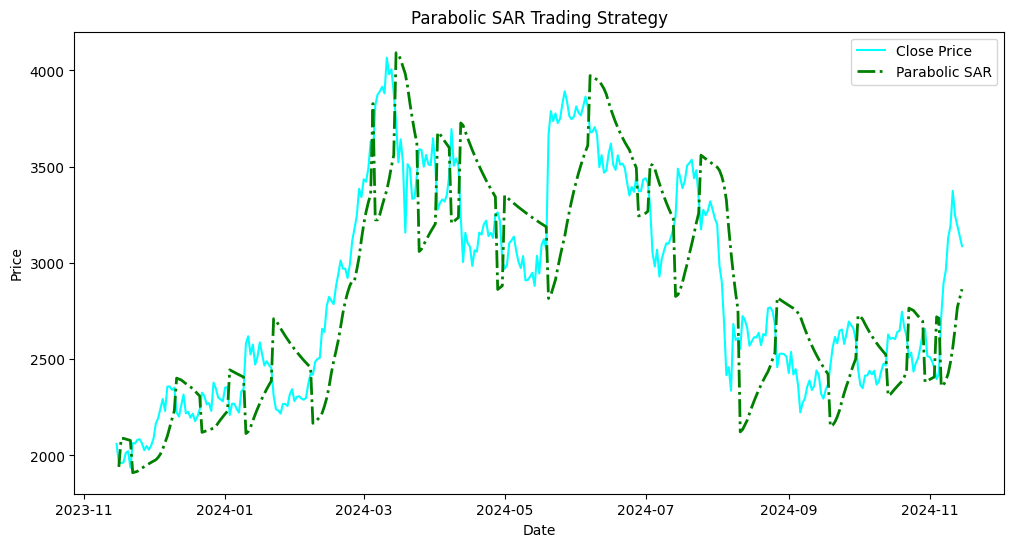

In [253]:
# Function to plot the strategy results
def plot_strategy_sar_only(data):
   plt.figure(figsize=(12, 6))
   plt.plot(data['Close'], label='Close Price', color='cyan')
   plt.plot(data['SAR'], label='Parabolic SAR', linewidth=2,  linestyle='dashdot', color='green')
   plt.title('Parabolic SAR Trading Strategy')
   plt.xlabel('Date')
   plt.ylabel('Price')
   plt.legend()
   plt.show()

plot_strategy_sar_only(strategy_data)

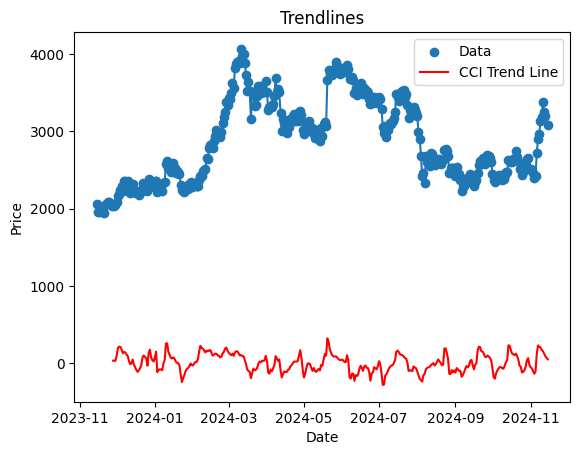

In [238]:
# Drawing a simple trendline
plt.plot(data['Close'])

x = range(len(data['Close']))
# Perform linear regression
slope, intercept = np.polyfit(x, data['Close'], 1)

# Plot the data and the trend line
plt.scatter(data.index, data['Close'], label='Data')
# Calculate CCI
data['cci'] = talib.CCI(data['High'], data['Low'], df['Close'], timeperiod=14)
plt.plot(data.index, data['cci'], color='red', label='CCI Trend Line')

# Add labels and title
plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Trendlines')
plt.legend()
plt.show()

n: Specifies the number of windows you want to create.
window_len: Specifies the length of each window (in this case, 5 data points).
windows: A tuple containing two elements:
The first element holds the price data for each window.
The second element holds the index values for each window.

In [265]:
import vectorbt as vbt
import pandas as pd

# Load data
symbols = ["BTC-USD"]
close = vbt.YFData.download(symbols, missing_index='drop').get('Close')

# Select 10 ranges from data, each one year long
split_close, split_idxs = close.vbt.rolling_split(window_len=60, n=10)


print(split_idxs)

[DatetimeIndex(['2014-09-17 00:00:00+00:00', '2014-09-18 00:00:00+00:00',
               '2014-09-19 00:00:00+00:00', '2014-09-20 00:00:00+00:00',
               '2014-09-21 00:00:00+00:00', '2014-09-22 00:00:00+00:00',
               '2014-09-23 00:00:00+00:00', '2014-09-24 00:00:00+00:00',
               '2014-09-25 00:00:00+00:00', '2014-09-26 00:00:00+00:00',
               '2014-09-27 00:00:00+00:00', '2014-09-28 00:00:00+00:00',
               '2014-09-29 00:00:00+00:00', '2014-09-30 00:00:00+00:00',
               '2014-10-01 00:00:00+00:00', '2014-10-02 00:00:00+00:00',
               '2014-10-03 00:00:00+00:00', '2014-10-04 00:00:00+00:00',
               '2014-10-05 00:00:00+00:00', '2014-10-06 00:00:00+00:00',
               '2014-10-07 00:00:00+00:00', '2014-10-08 00:00:00+00:00',
               '2014-10-09 00:00:00+00:00', '2014-10-10 00:00:00+00:00',
               '2014-10-11 00:00:00+00:00', '2014-10-12 00:00:00+00:00',
               '2014-10-13 00:00:00+00:00', '2014-

In [268]:
import vectorbt as vbt
import pandas as pd

# Create a sample price dataframe
price_data = pd.DataFrame({
    'price': [10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
})

# Split the price data into rolling windows
windows = price_data.vbt.rolling_split(n=3, window_len=5)

# Access the first window
first_window = windows

print(first_window)

(split_idx   0   1   2
0          10  12  15
1          11  13  16
2          12  14  17
3          13  15  18
4          14  16  19, [Index([0, 1, 2, 3, 4], dtype='int64', name='split_0'), Index([2, 3, 4, 5, 6], dtype='int64', name='split_1'), Index([5, 6, 7, 8, 9], dtype='int64', name='split_2')])


In [282]:
import vectorbt as vbt

start = '2022-1-01 UTC'  # crypto is in UTC
end = '2023-12-01 UTC'
cols = ['Open', 'High', 'Low', 'Close', 'Volume']
ohlcv = vbt.YFData.download("BTC-USD", start=start, end=end).get(cols)
ohlcv

,Open,High,Low,Close,Volume
Date,,,,,
2022-01-01 00:00:00+00:00,46311.746094,47827.312500,46288.484375,47686.812500,24582667004
2022-01-02 00:00:00+00:00,47680.925781,47881.406250,46856.937500,47345.218750,27951569547
2022-01-03 00:00:00+00:00,47343.542969,47510.726562,45835.964844,46458.117188,33071628362
2022-01-04 00:00:00+00:00,46458.851562,47406.546875,45752.464844,45897.574219,42494677905
2022-01-05 00:00:00+00:00,45899.359375,46929.046875,42798.222656,43569.003906,36851084859
...,...,...,...,...,...
2023-11-26 00:00:00+00:00,37796.828125,37820.300781,37162.750000,37479.121094,13744796068
2023-11-27 00:00:00+00:00,37454.191406,37559.355469,36750.128906,37254.167969,19002925720
2023-11-28 00:00:00+00:00,37247.992188,38368.480469,36891.089844,37831.085938,21696137014


In [280]:
ohlcv.vbt.ohlcv.plot()

FigureWidget({
    'data': [{'close': array([16967.1328125 , 17088.66015625, 16908.23632812, ..., 37831.0859375 ,
                              37858.4921875 , 37712.74609375]),
              'decreasing': {'line': {'color': '#d95f02'}},
              'high': array([17197.49804688, 17088.66015625, 17116.04101562, ..., 38368.48046875,
                             38366.11328125, 38141.75390625]),
              'increasing': {'line': {'color': '#1b9e76'}},
              'low': array([16888.38867188, 16877.88085938, 16888.140625  , ..., 36891.08984375,
                            37612.6328125 , 37531.140625  ]),
              'name': 'OHLC',
              'open': array([17168.00195312, 16968.68359375, 17090.09765625, ..., 37247.9921875 ,
                             37826.10546875, 37861.1171875 ]),
              'type': 'ohlc',
              'uid': 'b64a8d18-9d2a-460e-aa98-e0754597fced',
              'x': array([datetime.datetime(2022, 12, 1, 0, 0, tzinfo=datetime.timezone.utc),
      

Daily Price change BTC-USD

In [406]:
import mongodb_util
import pandas as pd

db = mongodb_util.MongodbUtil()
db.test_mongodb_setup()
# Fetch data from MongoDB
data = db.util_fetch_all_collection('candles_ts_1d_BTC-USD')

# Convert data to a Pandas DataFrame
df = pd.DataFrame(list(data))
df.set_index(pd.DatetimeIndex(df['start']), inplace=True)
df.sort_index(inplace=True)
print(df.columns)

df['close'] = np.array(df['close'].astype('str').astype('float64'))
df['volume'] = np.array(df['volume'].astype('str').astype('float64'))
df['open'] = np.array(df['open'].astype('str').astype('float64'))
df['high'] = np.array(df['high'].astype('str').astype('float64'))
df['low'] = np.array(df['low'].astype('str').astype('float64'))
#Daily Range Percentage feature (what's the percentage of the highest daily price from the lowest)
df['daily_range_pct'] =  (df['high'] - df['low'])/df['low'] * 100

# Creating the Price Change Percentage feature
df['price_change_pct'] = (df['close'] - df['open']) / df['open'] * 100

df['daily_closing_pct_chg'] = df['close'].pct_change() * 100
df.dropna(inplace=True)
df

Pinged your deployment. You successfully connected to MongoDB!
Index(['start', 'open', 'low', 'volume', '_id', 'high', 'close'], dtype='object')


,start,open,low,volume,_id,high,close,daily_range_pct,price_change_pct,daily_closing_pct_chg
start,,,,,,,,,,
2024-05-16 20:00:00,2024-05-16 20:00:00,65252.17,65113.46,11710.007239,6731a9241eee616023b42254,67500.00,67046.33,3.665202,2.749579,2.749563
2024-05-17 20:00:00,2024-05-17 20:00:00,67046.34,66624.06,3880.581140,6731a9241eee616023b42253,67407.79,66923.87,1.176347,-0.182665,-0.182650
2024-05-18 20:00:00,2024-05-18 20:00:00,66923.87,65852.02,3565.113462,6731a9241eee616023b42252,67701.91,66261.62,2.809162,-0.989557,-0.989557
2024-05-19 20:00:00,2024-05-19 20:00:00,66260.04,66057.03,20415.886917,6731a9241eee616023b42251,71560.90,71432.17,8.331997,7.805806,7.803235
2024-05-20 20:00:00,2024-05-20 20:00:00,71432.16,69146.01,16102.061325,6731a9241eee616023b42250,71980.00,70142.84,4.098559,-1.804957,-1.804971
...,...,...,...,...,...,...,...,...,...,...
2024-11-15 19:00:00,2024-11-15 19:00:00,91058.36,90069.21,6598.026930,673a4f072a65a4fcf458d9c9,91820.73,90636.24,1.944638,-0.463571,2.729844
2024-11-16 19:00:00,2024-11-16 19:00:00,90638.54,89400.00,3997.644464,673a4f072a65a4fcf458d9c8,91439.82,90166.00,2.281678,-0.521346,-0.518821
2024-11-17 19:00:00,2024-11-17 19:00:00,89877.11,89372.65,17340.771665,673e13cdb4e920173407a813,92674.80,90520.30,3.694810,0.715633,0.392942


The Daily Change Percentage measures how much the closing price of a stock has changed compared to its opening price, expressed as a percentage. It's a useful metric for understanding the daily performance of a stock.

Here's how you can calculate it:

Daily Change % = ((Close - Open) / Open) * 100
This formula calculates the percentage change from the opening price to the closing price, giving you a sense of the stock's performance over the day.

The Daily Percent Change measures the percentage change in the closing price of a stock from one day to the next. It's a useful metric for understanding the day-to-day volatility and performance of a stock.

Here's how you can calculate it:

Daily Percent Change = ((Today's Close - Yesterday's Close) / Yesterday's Close) * 100
In Pandas, you can calculate this using the pct_change() method, which automatically computes the percentage change between consecutive elements in a column.

The Price Change Range Percent expresses the price change range as a percentage of the opening price. This provides a normalized view of how much the stock price fluctuated relative to its starting point for the day.

Here's how you can calculate it:

Price Change Range Percent = ((High - Low) / Open) * 100
This formula gives you the percentage of the price range relative to the opening price, offering a sense of the day's volatility in percentage terms.

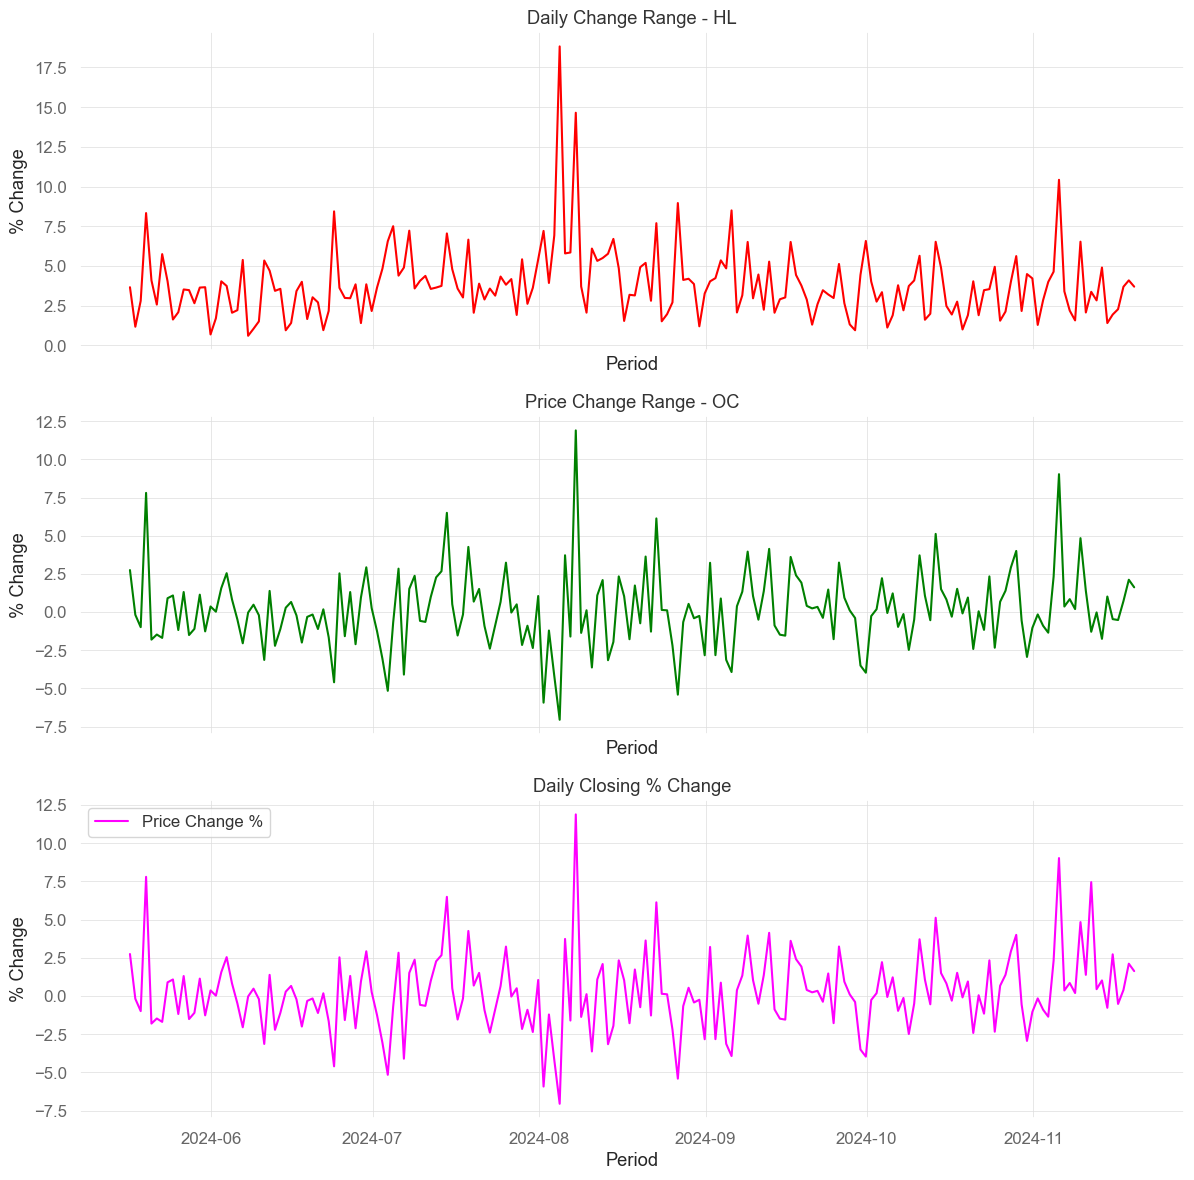

In [410]:
import matplotlib.pyplot as plt

# Create the figure and axes
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(12, 12))
ax1.set_title("Daily Change Range - HL")
ax1.plot(df['daily_range_pct'], color='red', label='Daily Range %')
ax1.set_xlabel("Period")
ax1.set_ylabel("% Change")

# Add title and labels
ax2.set_title("Price Change Range - OC")
ax2.plot(df['price_change_pct'], color='green', label='Price Change %')
ax2.set_xlabel('Period')
ax2.set_ylabel("% Change")

# Add title and labels
ax3.set_title("Daily Closing % Change")
ax3.plot(df['daily_closing_pct_chg'], color='magenta', label='Price Change %')
ax3.set_xlabel('Period')
ax3.set_ylabel("% Change")
# Customize
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

<Figure size 800x800 with 0 Axes>

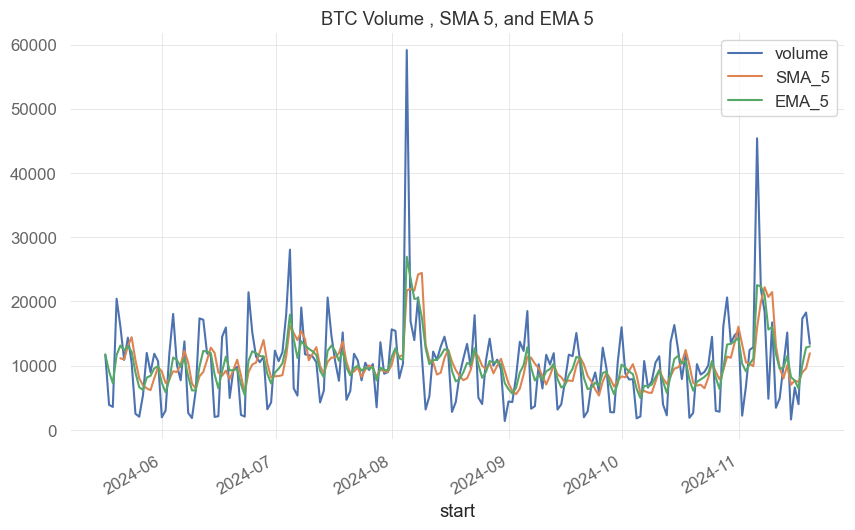

In [414]:
# Step 2: Calculate the 14-day SMA and EMA
df['SMA_5'] = df['volume'].rolling(window=5).mean()
df['EMA_5'] = df["volume"].ewm(span=5, adjust=False).mean()

# Step 3: Focus on data from the year 2018 for better visualization
#df_small = df.loc['2018']

# Step 4: Plot the Volume along with SMA and EMA
plt.figure(figsize=(12, 6))
df[['volume', 'SMA_5', 'EMA_5']].plot(title="BTC Volume , SMA 5, and EMA 5")
plt.show()

To calculate the volatility as a percentage, you can express the daily price range relative to the opening price. This gives you a sense of how significant the price swings are compared to the starting price of the day.

Here's how you can calculate it:

Volatility Percent = ((High - Low) / Open) * 100
This formula gives you the percentage change in price relative to the opening price, providing a normalized measure of volatility.

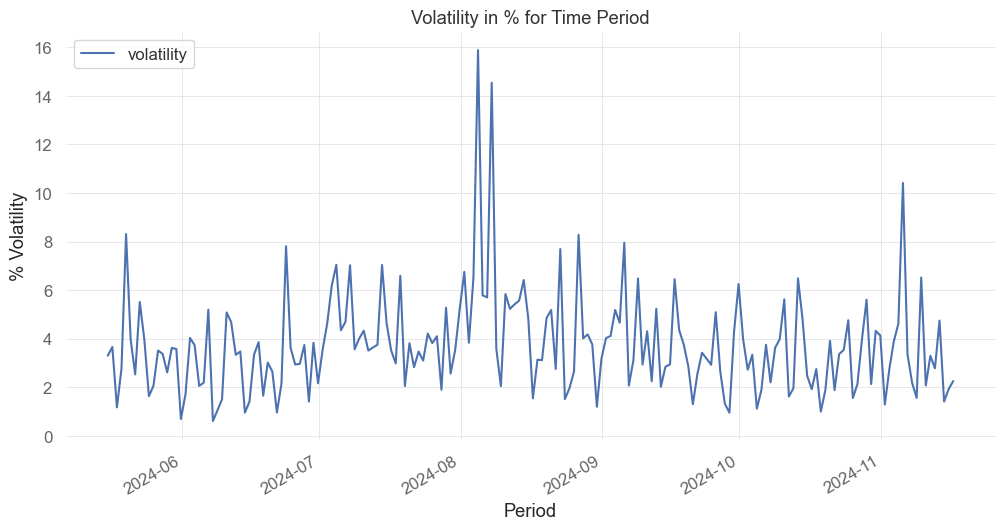

In [389]:
df['volatility'] = ((df['high']-df['low'])/df['open']) * 100
df[['volatility']].plot(figsize=(12, 6), title='Volatility in % for Time Period')
plt.legend(loc='upper left')
plt.xlabel('Period')
plt.ylabel('% Volatility')
plt.show()

cumsum (Cumulative Sum): This function calculates the cumulative sum of a column. For each element, it adds up all the previous elements in the column, including the current one.
[1, 2, 3, 4] => cumsum([1, 2, 3, 4]) => [1, 3, 6, 10]

cumprod (Cumulative Product): This function calculates the cumulative product of a column. For each element, it multiplies all the previous elements in the column, including the current one.
[1, 2, 3, 4] => cumsum([1, 2, 3, 4]) => [1, 2, 6, 24]

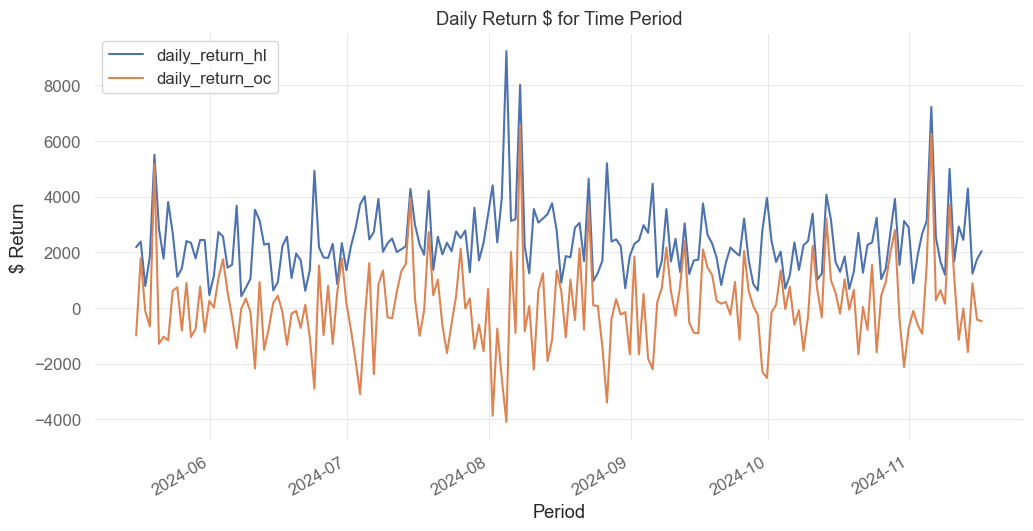

In [390]:
df['daily_return_hl'] = df['high'] - df['low']
df['daily_return_oc'] = df['close'] - df['open']
df[['daily_return_hl', 'daily_return_oc']].plot(figsize=(12, 6), title='Daily Return $ for Time Period')
plt.legend(loc='upper left')
plt.xlabel('Period')
plt.ylabel('$ Return')
plt.show()


In [391]:
print(f"Total Returns HL:",df['daily_return_hl'].cumsum())

Total Returns HL: start
2024-05-15 20:00:00      2184.33
2024-05-16 20:00:00      4570.87
2024-05-17 20:00:00      5354.60
2024-05-18 20:00:00      7204.49
2024-05-19 20:00:00     12708.36
                         ...    
2024-11-12 19:00:00    434271.84
2024-11-13 19:00:00    438564.58
2024-11-14 19:00:00    439793.62
2024-11-15 19:00:00    441545.14
2024-11-16 19:00:00    443584.96
Name: daily_return_hl, Length: 186, dtype: float64


In [383]:
print(f"Total Returns OC :",df['daily_return_oc'].cumsum())

Total Returns OC : start
2024-05-15 20:00:00     -992.50
2024-05-16 20:00:00      801.66
2024-05-17 20:00:00      679.19
2024-05-18 20:00:00       16.94
2024-05-19 20:00:00     5189.07
                         ...   
2024-11-12 19:00:00    14174.80
2024-11-13 19:00:00    12587.86
2024-11-14 19:00:00    13476.66
2024-11-15 19:00:00    13054.54
2024-11-16 19:00:00    12582.00
Name: daily_return_oc, Length: 186, dtype: float64


Identifying Golden Cross and Death Cross
In trading, golden and death crosses are defined as follows:

Golden Cross: Occurs when a short-term SMA (50-day) crosses above a long-term SMA (200-day), indicating a potential upward trend.
Death Cross: Occurs when a short-term SMA (50-day) crosses below a long-term SMA (200-day), indicating a potential downward trend.

Explanation:

Signal Column: We create a 'Signal' column to store initial values as 0.
Golden Cross Signal: When the 50-day SMA crosses above the 200-day SMA, we set the 'Signal' to 1.
Death Cross Signal: When the 50-day SMA crosses below the 200-day SMA, we set the 'Signal' to -1.
Crossover Column: We create a 'Crossover' column to store the points where the signal changes (differs from the previous day), indicating a crossover event.

Check for Golden Cross: If the 'Crossover' value is 2, plot a green dot at the index on the 50-day SMA curve.
Check for Death Cross: If the 'Crossover' value is -2, plot a red dot at the index on the 50-day SMA curve.

Index(['Close', 'Volume', 'Open', 'High'], dtype='object')


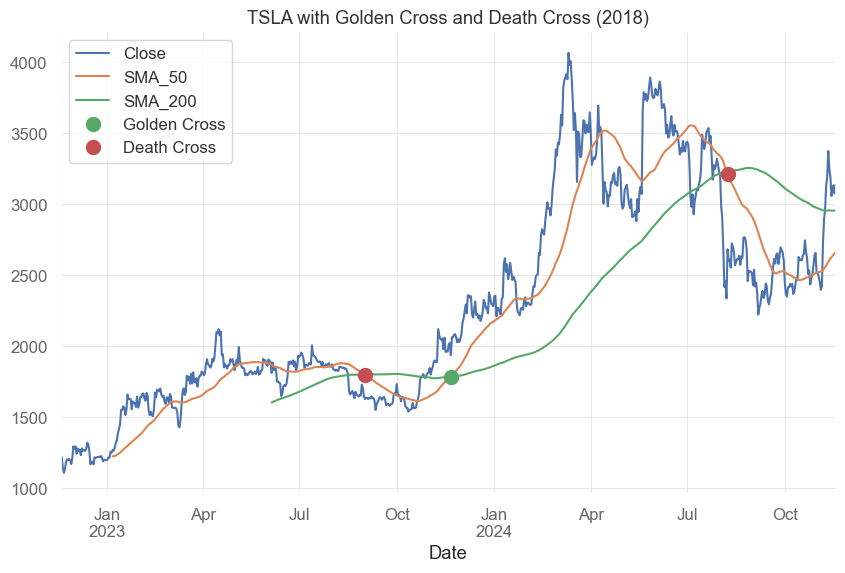

In [354]:
ticker = 'ETH-USD'
time_period = '2y'

btc = yf.Ticker(ticker)
data = btc.history(period=time_period)

# Display the first few rows of the data
df = pd.DataFrame({
    'Close': data['Close'],
    'Volume': data['Volume'],
    'Open': data['Open'],
    'High': data['High']
})
print(df.columns)
df = df.astype({
    'Close': 'float64',
    'Volume': 'float64',
    'Open': 'float64',
    'High': 'float64'
},copy=False)

# Calculate 50-day and 200-day SMAs
df['SMA_50'] = df['Close'].rolling(window=50).mean()
df['SMA_200'] = df['Close'].rolling(window=200).mean()

# Identifying the "Golden Cross" and "Death Cross"
df['Signal'] = 0  # Default value
df.loc[df['SMA_50'] > df['SMA_200'], 'Signal'] = 1
df.loc[df['SMA_50'] < df['SMA_200'], 'Signal'] = -1

# Creating a column to mark crossover points
df['Crossover'] = df['Signal'].diff()

# Using a smaller date range for better visualization
#df_small = df.loc['2018']

# Plot with Golden Cross and Death Cross
df[['Close', 'SMA_50', 'SMA_200']].plot( title="TSLA with Golden Cross and Death Cross (2018)")

# Highlighting Golden Cross and Death Cross points
plt.plot(df[df['Crossover'] == 2]['SMA_50'], 'go', markersize=10,  label='Golden Cross')
plt.plot(df[df["Crossover"] == -2]['SMA_50'], 'ro',markersize=10,  label='Death Cross')
plt.legend()
plt.show()

VWAP
Volume Weighted Average Price (VWAP) is a trading benchmark that gives traders insight into both the price and volume of trades for a particular stock. It represents the average price a stock has traded at throughout the day, weighted by volume.
VWAP is used by traders to identify the average price at which a stock was traded over a given period, reflecting both the price and the traded volume. It helps in determining the efficiency of stock execution by comparing it against the market's average.

The VWAP is calculated using the cumulative sum (the running total) of the volume and the volume-weighted prices:

VWAP = ∑i = 1 n (Pi × Vi) ∑i = 1n Vi

VWAP = Cumulative (Price * Volume) /Cumulative Volume

where:

Pi is the price of the stock

Vi is the volume of trades at each i-th period.

Calculate the typical price:

For a given period, calculate the average of the high, low, and close prices using the formula: (High + Low + Close) / 3

The Volume-Weighted Average Price (VWAP) is typically used on intraday timeframes, such as one-minute, five-minute, or 15-minute, and is most effective for short-term trading. The VWAP is calculated using intraday data and resets daily

Pinged your deployment. You successfully connected to MongoDB!
Index(['start', '_id', 'high', 'close', 'volume', 'open', 'low'], dtype='object')


<Figure size 1200x600 with 0 Axes>

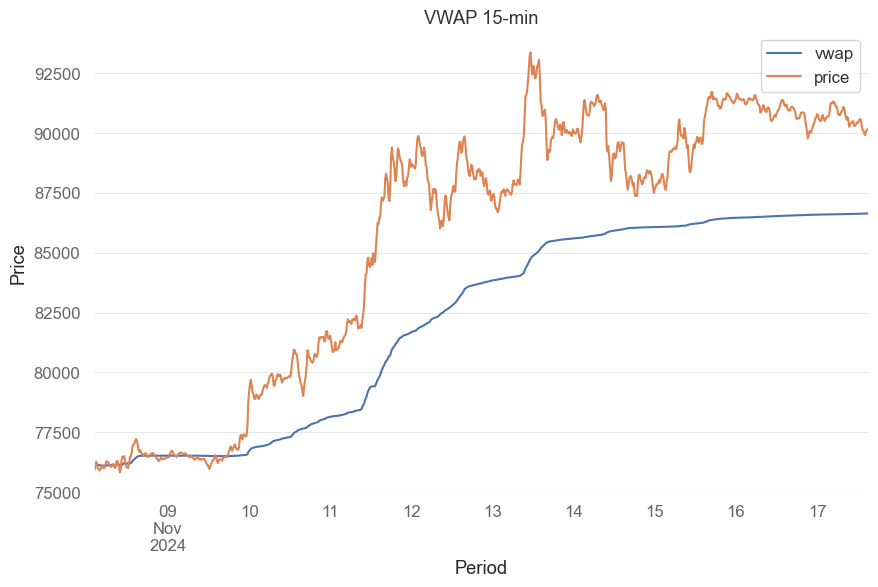

In [363]:
import mongodb_util
import pandas as pd

db = mongodb_util.MongodbUtil()
db.test_mongodb_setup()
# Fetch data from MongoDB
data = db.util_fetch_all_collection('candles_ts_15min_BTC-USD')

# Convert data to a Pandas DataFrame
df = pd.DataFrame(list(data))
df.set_index(pd.DatetimeIndex(df['start']), inplace=True)
df.sort_index(inplace=True)
print(df.columns)

df['close'] = np.array(df['close'].astype('str').astype('float64'))
df['volume'] = np.array(df['volume'].astype('str').astype('float64'))
df['open'] = np.array(df['open'].astype('str').astype('float64'))
df['high'] = np.array(df['high'].astype('str').astype('float64'))
df['low'] = np.array(df['low'].astype('str').astype('float64'))

df['price'] = np.round((df['close'] + df['open'] + df['high'])/3,4)
df['vwap'] = np.cumsum(df['price'] * df['volume'])/np.cumsum(df['volume'])
plt.figure(figsize=(12, 6))
df[['vwap','price']].plot(title='VWAP 15-min')
plt.xlabel('Period')
plt.ylabel('Price')
plt.legend()
plt.show()